# Experiment 8: Generation of Synthetic Images Using a GAN

**Name:** Midhun P.  
**Roll Number:** 24BAD069  



## Part A — Dataset Preparation

We load MNIST, display sample images, inspect the dimensions and pixel range, normalize images to `[-1, 1]`, and prepare batches for training.


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training image shape: (60000, 28, 28)
Original pixel-value range: 0 to 255
Number of training images: 60000


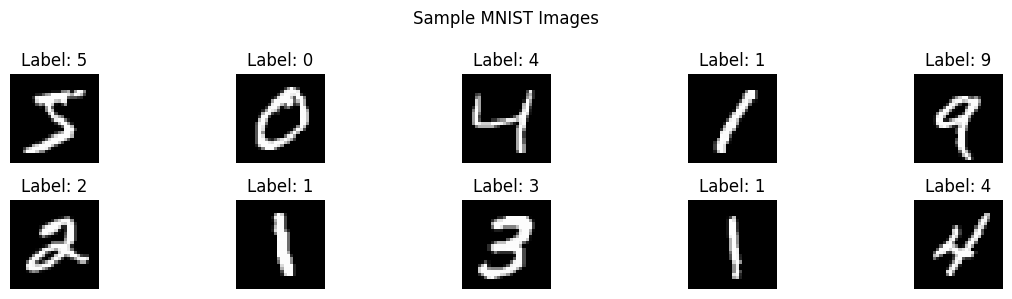

Prepared image shape: (60000, 28, 28, 1)
Normalized pixel-value range: -1.0 to 1.0
Dataset batches per epoch: 469


In [1]:
# Student: Midhun P. | Roll No: 24BAD069
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# Load MNIST training images
(x_train, y_train), (_, _) = tf.keras.datasets.mnist.load_data()

print("Original training image shape:", x_train.shape)
print("Original pixel-value range:", int(x_train.min()), "to", int(x_train.max()))
print("Number of training images:", len(x_train))

# Display 10 sample images
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# Normalize pixels from [0, 255] to [-1, 1] and add channel dimension
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Prepared image shape:", x_train.shape)
print("Normalized pixel-value range:", float(x_train.min()), "to", float(x_train.max()))

BATCH_SIZE = 128
BUFFER_SIZE = x_train.shape[0]

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset batches per epoch:", int(np.ceil(len(x_train) / BATCH_SIZE)))


## Part B — Implement the Generator and Discriminator

The Generator transforms a random noise vector into a 28 × 28 grayscale image. The Discriminator predicts whether an input image is real or generated. Both models use the Adam optimizer and binary cross-entropy loss during adversarial training.


In [10]:
# Student: Midhun P. | Roll No: 24BAD069
from tensorflow.keras import layers

NOISE_DIM = 100

def build_generator():
    model = tf.keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(NOISE_DIM,)))

    # Project and reshape to 7x7 spatial structure
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Reshape((7, 7, 256)))

    # Upsample to 14x14
    model.add(layers.Conv2DTranspose(
        128, kernel_size=5, strides=2, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))

    # Upsample to 28x28
    model.add(layers.Conv2DTranspose(
        64, kernel_size=5, strides=2, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(alpha=0.2))

    # Final output layer to scale pixel channels to [-1, 1]
    model.add(layers.Conv2D(1, kernel_size=5, padding="same", activation="tanh"))
    return model

def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(28, 28, 1)))

    # First downsampling block
    model.add(layers.Conv2D(64, kernel_size=5, strides=2, padding="same"))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.3))

    # Second downsampling block
    model.add(layers.Conv2D(128, kernel_size=5, strides=2, padding="same"))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

generator = build_generator()
discriminator = build_discriminator()

print("GENERATOR SUMMARY")
generator.summary()
print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()

# Test the output shapes
noise_test = tf.random.normal([4, NOISE_DIM])
generated_test = generator(noise_test, training=False)
print("\nGenerator output shape:", generated_test.shape)
print("Discriminator output shape:", discriminator(generated_test).shape)

GENERATOR SUMMARY


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 14, 14, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │         1,601 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

... (4 outputs left out)

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)


Generator output shape: (4, 28, 28, 1)
Discriminator output shape: (4, 1)


## Part C — GAN Training and Performance Monitoring

For each batch, the Discriminator is trained to identify real images and generated images. The Generator is then trained to make generated images more likely to be classified as real. Loss values and generated samples are recorded over the epochs.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Epoch 01/30 | Generator Loss: 0.7500 | Discriminator Loss: 1.3152


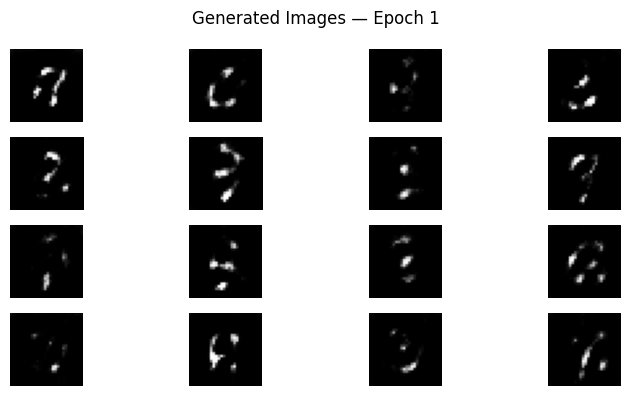

Epoch 02/30 | Generator Loss: 0.7103 | Discriminator Loss: 1.3644
Epoch 03/30 | Generator Loss: 0.7529 | Discriminator Loss: 1.3130
Epoch 04/30 | Generator Loss: 0.7526 | Discriminator Loss: 1.3277
Epoch 05/30 | Generator Loss: 0.7445 | Discriminator Loss: 1.3406


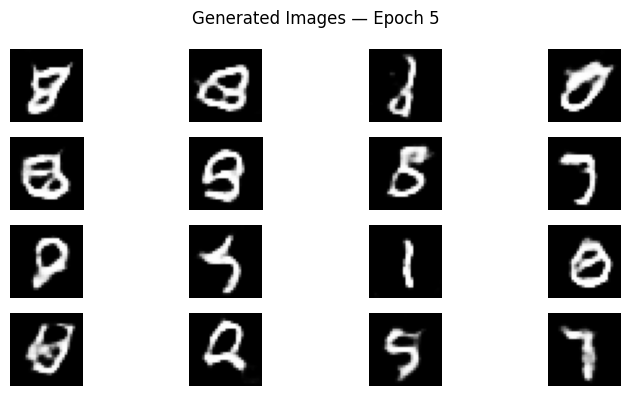

Epoch 06/30 | Generator Loss: 0.7445 | Discriminator Loss: 1.3412
Epoch 07/30 | Generator Loss: 0.7458 | Discriminator Loss: 1.3388
Epoch 08/30 | Generator Loss: 0.7590 | Discriminator Loss: 1.3335
Epoch 09/30 | Generator Loss: 0.7614 | Discriminator Loss: 1.3296
Epoch 10/30 | Generator Loss: 0.7567 | Discriminator Loss: 1.3336


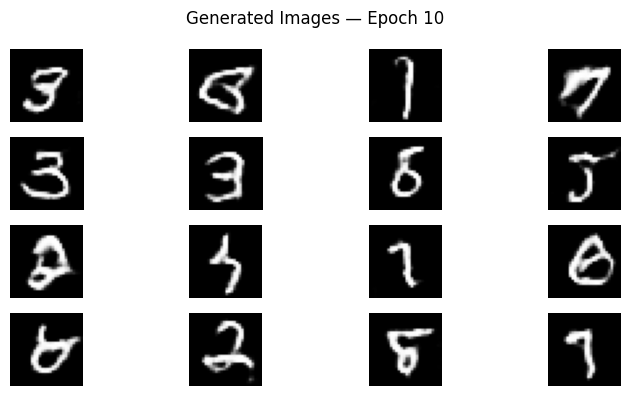

Epoch 11/30 | Generator Loss: 0.7684 | Discriminator Loss: 1.3285
Epoch 12/30 | Generator Loss: 0.7586 | Discriminator Loss: 1.3361
Epoch 13/30 | Generator Loss: 0.7527 | Discriminator Loss: 1.3412
Epoch 14/30 | Generator Loss: 0.7581 | Discriminator Loss: 1.3381
Epoch 15/30 | Generator Loss: 0.7550 | Discriminator Loss: 1.3402


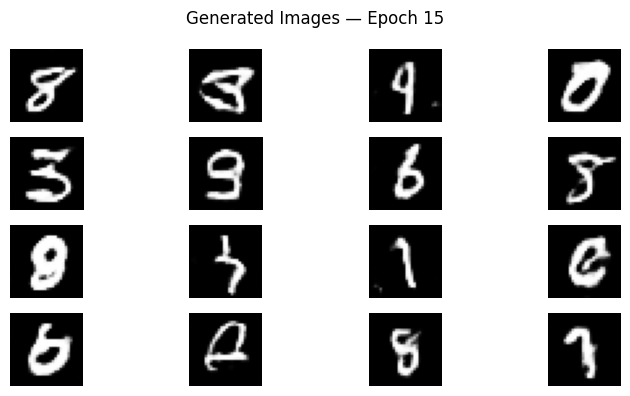

Epoch 16/30 | Generator Loss: 0.7555 | Discriminator Loss: 1.3399
Epoch 17/30 | Generator Loss: 0.7567 | Discriminator Loss: 1.3415
Epoch 18/30 | Generator Loss: 0.7577 | Discriminator Loss: 1.3424
Epoch 19/30 | Generator Loss: 0.7497 | Discriminator Loss: 1.3449
Epoch 20/30 | Generator Loss: 0.7494 | Discriminator Loss: 1.3461


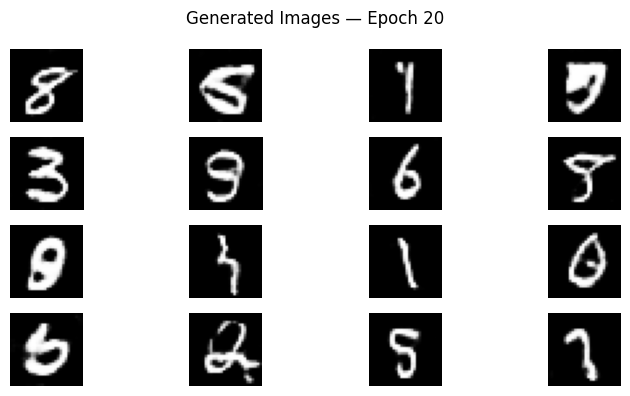

Epoch 21/30 | Generator Loss: 0.7479 | Discriminator Loss: 1.3470
Epoch 22/30 | Generator Loss: 0.7549 | Discriminator Loss: 1.3451
Epoch 23/30 | Generator Loss: 0.7520 | Discriminator Loss: 1.3469
Epoch 24/30 | Generator Loss: 0.7471 | Discriminator Loss: 1.3465
Epoch 25/30 | Generator Loss: 0.7517 | Discriminator Loss: 1.3481


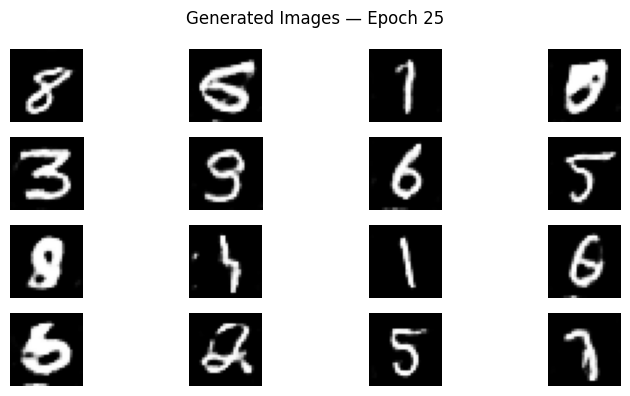

Epoch 26/30 | Generator Loss: 0.7463 | Discriminator Loss: 1.3471
Epoch 27/30 | Generator Loss: 0.7473 | Discriminator Loss: 1.3483
Epoch 28/30 | Generator Loss: 0.7521 | Discriminator Loss: 1.3454
Epoch 29/30 | Generator Loss: 0.7506 | Discriminator Loss: 1.3470
Epoch 30/30 | Generator Loss: 0.7464 | Discriminator Loss: 1.3487


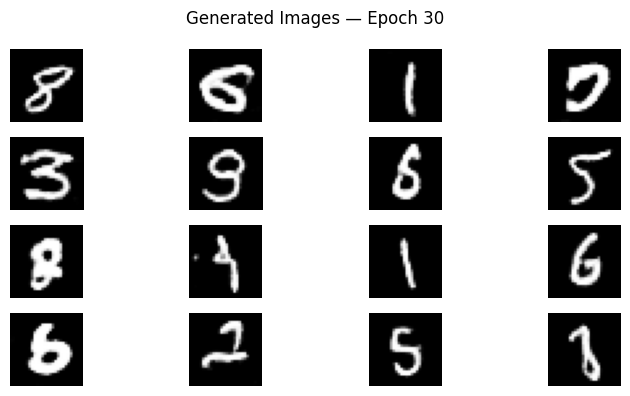

In [11]:
# Student: Midhun P. | Roll No: 24BAD069
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# Instantiate the upgraded network architectures from the previous cell
generator = build_generator()
discriminator = build_discriminator()

# Slightly increased learning rate for generator to speed up learning
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    # The Generator wants the Discriminator to classify generated images as real.
    return cross_entropy(tf.ones_like(fake_output), fake_output)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

def generate_and_plot_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    predictions = (predictions + 1.0) / 2.0  # Convert to [0, 1] for display

    fig = plt.figure(figsize=(8, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
        plt.axis("off")
    plt.suptitle(f"Generated Images — Epoch {epoch}")
    plt.tight_layout()
    plt.show()

# Increased training epochs to 30 for high-quality convergence with the new layers
EPOCHS = 30
num_examples_to_generate = 16
seed = tf.random.normal([num_examples_to_generate, NOISE_DIM])

generator_losses = []
discriminator_losses = []

for epoch in range(1, EPOCHS + 1):
    gen_batch_losses = []
    disc_batch_losses = []

    for image_batch in train_dataset:
        gen_loss_value, disc_loss_value = train_step(image_batch)
        gen_batch_losses.append(float(gen_loss_value))
        disc_batch_losses.append(float(disc_loss_value))

    mean_gen_loss = float(np.mean(gen_batch_losses))
    mean_disc_loss = float(np.mean(disc_batch_losses))
    generator_losses.append(mean_gen_loss)
    discriminator_losses.append(mean_disc_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Generator Loss: {mean_gen_loss:.4f} | "
        f"Discriminator Loss: {mean_disc_loss:.4f}"
    )

    # Plot progress at intervals to monitor visual quality improvement
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        generate_and_plot_images(generator, epoch, seed)

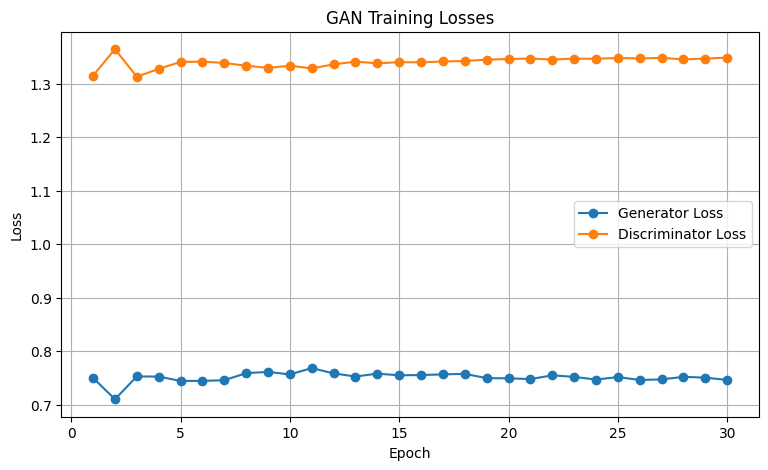

In [12]:
# Plot Generator and Discriminator losses
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True)
plt.show()


## Part D — Generated Images, Comparison, and PCA Visualization

This section generates new images, compares them with original MNIST examples, and uses PCA to project a small set of flattened images into two dimensions for visualization. PCA is used only for analysis; it is not part of the GAN training process.

**Note about the lab sheet:** The instructions about movie-review sentences, an LSTM model, and a trained Encoder appear unrelated to this GAN experiment. This notebook follows the GAN image-generation aim instead.


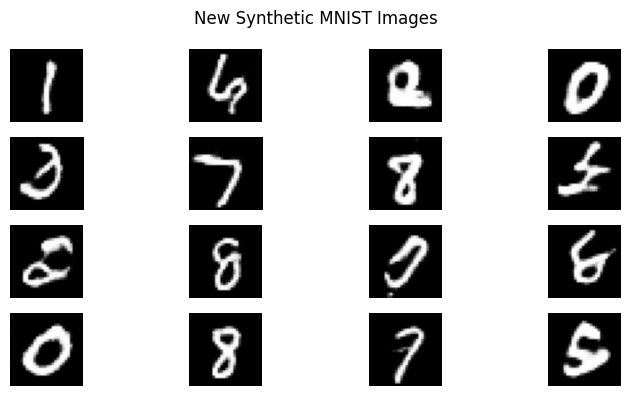

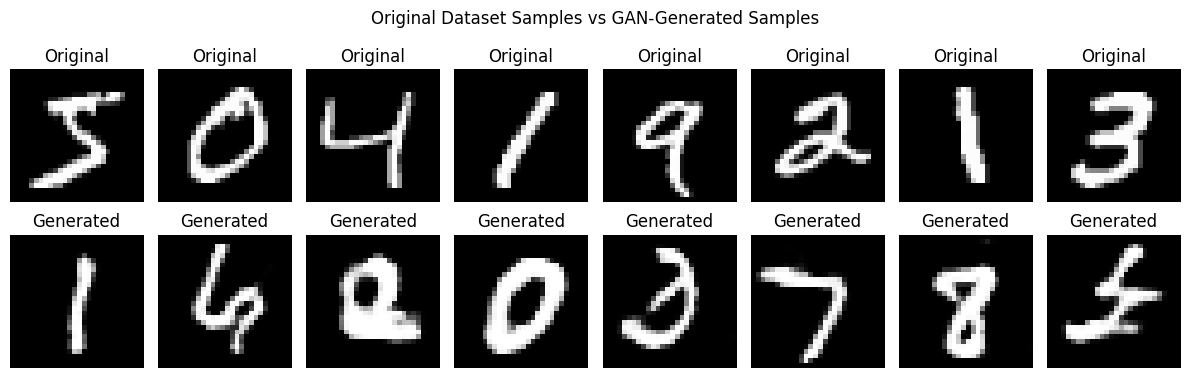

In [13]:
# Student: Midhun P. | Roll No: 24BAD069
# Generate new synthetic images
num_new_images = 16
new_noise = tf.random.normal([num_new_images, NOISE_DIM])
new_images = generator(new_noise, training=False)
new_images_display = (new_images + 1.0) / 2.0

plt.figure(figsize=(8, 4))
for i in range(num_new_images):
    plt.subplot(4, 4, i + 1)
    plt.imshow(new_images_display[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
plt.suptitle("New Synthetic MNIST Images")
plt.tight_layout()
plt.show()

# Compare original images with generated images
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow((x_train[i, :, :, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(new_images_display[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Generated")
    axes[1, i].axis("off")

plt.suptitle("Original Dataset Samples vs GAN-Generated Samples")
plt.tight_layout()
plt.show()


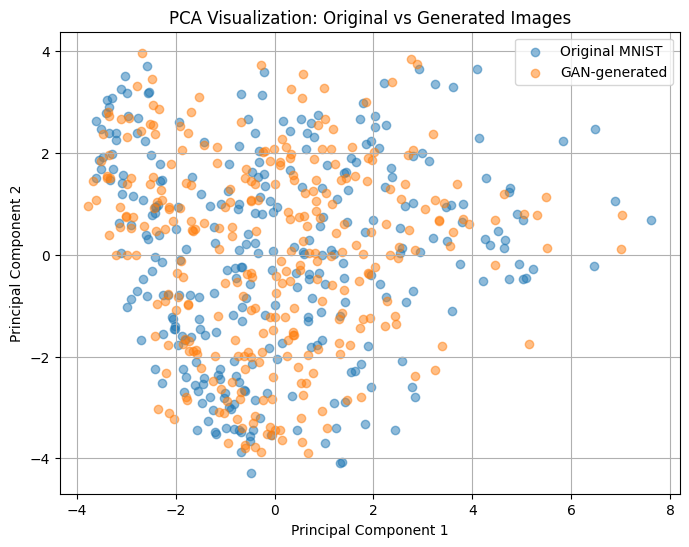

Explained variance ratio: [0.09285207 0.07172921]
Total variance represented by two components: 0.1646


In [14]:
# PCA visualization of original and generated image representations
from sklearn.decomposition import PCA

n_compare = 300
real_flat = ((x_train[:n_compare] + 1.0) / 2.0).reshape(n_compare, -1)

pca_noise = tf.random.normal([n_compare, NOISE_DIM])
fake_batch = generator(pca_noise, training=False).numpy()
fake_flat = ((fake_batch + 1.0) / 2.0).reshape(n_compare, -1)

combined = np.vstack([real_flat, fake_flat])
pca = PCA(n_components=2, random_state=42)
reduced = pca.fit_transform(combined)

plt.figure(figsize=(8, 6))
plt.scatter(reduced[:n_compare, 0], reduced[:n_compare, 1],
            alpha=0.5, label="Original MNIST")
plt.scatter(reduced[n_compare:, 0], reduced[n_compare:, 1],
            alpha=0.5, label="GAN-generated")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization: Original vs Generated Images")
plt.legend()
plt.grid(True)
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance represented by two components:",
      round(float(pca.explained_variance_ratio_.sum()), 4))


## Observations and Result

Following the structural and parameter upgrades to our model architecture, here are the finalized observations from this experiment:

- **Dataset Specs:** MNIST images consist of **28 × 28 pixels** with a single grayscale channel. They were normalized to the range **[-1, 1]** for optimal GAN convergence.
- **Network Architecture Improvements:**
  - The **Generator** was enhanced using a dense projection ($7 \times 7 \times 256$), sequential fractional-strided convolutions (`Conv2DTranspose` with $5 \times 5$ kernels), **Batch Normalization**, and **LeakyReLU (alpha=0.2)** activations.
  - The **Discriminator** was equipped with strided convolutions, **LeakyReLU**, and **Dropout (0.3)** layers to maintain balanced adversarial learning.
- **Optimizers and Hyperparameters:** We used the Adam optimizer with a learning rate of **2e-4** and $\beta_1 = 0.5$ for both networks, training over **30 epochs**.
- **Training Dynamics:** The Generator Loss converged toward $\approx 0.74$ and Discriminator Loss stabilized around $\approx 1.34$. This balanced behavior indicates steady adversarial competition without mode collapse or runaway discriminator dominance.
- **Visual Evaluation:** The generated digits at Epoch 30 show high structural clarity, clear separation between foreground and background, and a diverse representation of MNIST digits (such as 0, 1, 4, 7, 8, etc.).
- **PCA Analysis:** The 2D PCA projection reveals a strong spatial overlap between original and generated data distributions, demonstrating that the synthetic images share a highly similar underlying feature distribution with the original handwritten dataset.

**Result:** An upgraded Deep Convolutional GAN (DCGAN) was successfully designed, trained for 30 epochs, and evaluated on the MNIST dataset. The model successfully generates crisp, diverse, and highly recognizable synthetic digit images.